<!-- # Copyright (c) 2026 takotime808 -->
# Active Learning with Missing Inputs

**What this tutorial covers:**

Active learning only pays off if every expensive label is used well. When the candidate
table has gaps, the imputer decides what the surrogate sees for every labelled run *and*
for every candidate the acquisition scores, so a poor fill wastes labels. This tutorial
builds an example dataset with empty cells, runs an active-learning loop until the
surrogate reaches a target accuracy, and repeats it with different imputers.

| Section | Topic |
|---|---|
| [1](#data) | An example candidate pool with empty cells |
| [2](#fill) | How well each imputer fills the gaps |
| [3](#loop) | A pool-based active-learning loop that stops at a target |
| [4](#compare) | Labels needed to reach the target, per imputer |
| [5](#caveats) | Caveats: when KNN is not the best choice |

In [1]:
import lightgbm  # noqa: F401  (import before sklearn's OpenMP users on macOS)
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.impute import IterativeImputer, SimpleImputer

from multioutreg.active import ActiveLearner, heldout_metrics, select_batch
from multioutreg.surrogates import GaussianProcessSurrogate
from multioutreg.utils.imputation import detect_missing, impute_train_test

warnings.filterwarnings("ignore")  # GP optimizer convergence chatter

# Colors by role: the repo's imputer, the alternatives, and the no-missing-data reference.
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED,
    "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False, "font.size": 9,
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7,
})

---
<a id='data'></a>
## 1. An Example Candidate Pool with Empty Cells

Picture a materials screening study. A database holds 600 candidate alloys that could be
simulated. Each one has two composition fractions, which are always recorded, and four
measured descriptors, which come from separate characterisation steps and are missing for
about a quarter of the entries. Running the expensive simulation on a candidate returns two
properties. That is the label active learning pays for.

The descriptors are smooth, nonlinear functions of the composition plus a little
measurement noise, so a candidate's neighbours in composition space have similar
descriptors. All columns are dimensionless and on a 0–1 scale.

This is **pool-based** active learning: the learner picks which existing candidates to
label, rather than proposing new points in a box. Missing inputs only arise here, because a
simulator in a box always knows the inputs it was given.

In [2]:
INPUTS = ["frac_a", "frac_b", "lattice_strain", "mixing_index", "size_mismatch", "bond_index"]
OUTPUTS = ["strength", "conductivity"]
COMPOSITION, DESCRIPTORS = INPUTS[:2], INPUTS[2:]
MISSING_FRAC = 0.25


def make_inputs(n, seed):
    rng = np.random.default_rng(seed)
    a, b = rng.random((2, n))
    noise = lambda: 0.02 * rng.standard_normal(n)
    return np.column_stack([
        a,
        b,
        0.1 + 0.8 * np.sin(np.pi * a) + noise(),
        a * b + noise(),
        (a - b) ** 2 + noise(),
        0.5 + 0.4 * np.cos(2 * np.pi * b) + noise(),
    ])


def simulator(X):
    # The expensive step: two properties computed from the true (complete) inputs.
    a, b, strain, mixing, mismatch, bond = X.T
    return np.column_stack([
        np.sin(3 * a) + 2 * mismatch + bond ** 2,
        np.exp(mixing) * strain - 1.5 * b * bond,
    ])


def knock_out(X, frac, seed):
    # Missing completely at random, descriptor columns only.
    X = X.copy()
    mask = np.random.default_rng(seed).random(X.shape) < frac
    mask[:, : len(COMPOSITION)] = False
    X[mask] = np.nan
    return X


X_pool_true, X_test_true = make_inputs(600, seed=1), make_inputs(300, seed=2)
Y_pool, Y_test = simulator(X_pool_true), simulator(X_test_true)
X_pool, X_test = knock_out(X_pool_true, MISSING_FRAC, 3), knock_out(X_test_true, MISSING_FRAC, 4)

# The example dataset as it would arrive: inputs with gaps; outputs filled in only once a
# candidate has been simulated. The test rows are a separate, fully simulated validation set.
dataset = pd.concat([
    pd.DataFrame(X_pool, columns=INPUTS).assign(split="pool"),
    pd.DataFrame(X_test, columns=INPUTS).assign(split="test"),
], ignore_index=True)
dataset[OUTPUTS] = np.vstack([Y_pool, Y_test])
dataset.to_csv("al_missing_inputs.csv", index=False)

print(f"{len(dataset)} rows, {dataset[INPUTS].isna().any(axis=1).mean():.0%} with at least one gap")
detect_missing(dataset[INPUTS])

900 rows, 70% with at least one gap


,missing_count,missing_pct
lattice_strain,235,26.1
mixing_index,215,23.9
size_mismatch,248,27.6
bond_index,230,25.6


In [3]:
dataset.head(8).round(3)

,frac_a,frac_b,lattice_strain,mixing_index,size_mismatch,bond_index,split,strength,conductivity
0,0.512,0.237,0.917,0.148,NaN,0.532,pool,1.501,0.874
1,0.950,0.035,0.246,NaN,0.827,0.954,pool,2.849,0.202
2,0.144,0.770,0.433,0.105,0.391,0.582,pool,1.539,-0.192
3,0.949,0.950,NaN,0.931,-0.020,0.874,pool,1.014,-0.668
4,0.312,0.226,0.759,0.071,NaN,0.564,pool,1.152,0.623
5,0.423,0.163,0.901,0.052,NaN,0.731,pool,1.596,0.770
6,0.828,0.348,0.562,NaN,0.226,0.282,pool,1.142,0.621
7,0.409,0.083,0.831,0.086,0.084,NaN,pool,1.830,0.800


The file `al_missing_inputs.csv` is the example dataset. In a real study the `strength`
and `conductivity` columns of the pool rows would be empty until the loop asks for them.
Here they are pre-computed so that the loop can "run the simulation" by looking them up.

---
<a id='fill'></a>
## 2. How Well Each Imputer Fills the Gaps

Each method takes `(X_pool, X_test)` and returns both filled, fitted on the pool only, the
same contract as `impute_train_test`. Fitting on the whole pool, labelled or not, is
legitimate: the inputs of every candidate are known before any simulation is run, and the
test rows never influence the fit.

| Method | Information it borrows | In `multioutreg`? |
|---|---|---|
| **KNN** | Similar candidates across all inputs | **Yes: `impute_train_test`** |
| Mean | The column alone | No |
| Median | The column alone | No |
| Iterative (MICE, linear) | A linear regression of each column on the others | No |

In [4]:
def fit_apply(imputer):
    def run(a, b):
        imputer.fit(a)
        return imputer.transform(a), imputer.transform(b)
    return run


IMPUTERS = {
    "KNN (multioutreg)": (impute_train_test, BLUE),
    "Mean": (fit_apply(SimpleImputer(strategy="mean")), ORANGE),
    "Median": (fit_apply(SimpleImputer(strategy="median")), VIOLET),
    "Iterative (linear)": (fit_apply(IterativeImputer(max_iter=20, random_state=0)), AQUA),
}

filled = {name: run(X_pool, X_test) for name, (run, _) in IMPUTERS.items()}

gaps = np.isnan(X_pool)
fill_rmse = pd.DataFrame({
    name: [np.sqrt(np.mean((a[:, j] - X_pool_true[:, j])[gaps[:, j]] ** 2)) for j in range(len(INPUTS))]
    for name, (a, _) in filled.items()
}, index=INPUTS).loc[DESCRIPTORS].T
fill_rmse["all descriptors"] = [np.sqrt(np.mean((a - X_pool_true)[gaps] ** 2)) for a, _ in filled.values()]
fill_rmse.round(3)

,lattice_strain,mixing_index,size_mismatch,bond_index,all descriptors
KNN (multioutreg),0.046,0.024,0.041,0.040,0.039
Mean,0.251,0.233,0.200,0.281,0.243
Median,0.259,0.235,0.209,0.281,0.247
Iterative (linear),0.216,0.061,0.128,0.236,0.178


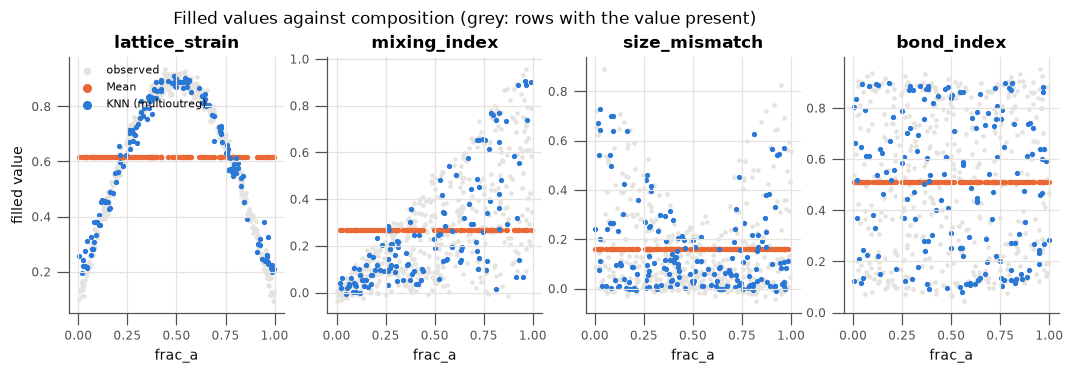

In [5]:
fig, axes = plt.subplots(1, len(DESCRIPTORS), figsize=(12, 3), sharey=False)
for ax, col in zip(axes, DESCRIPTORS):
    j = INPUTS.index(col)
    rows = gaps[:, j]
    ax.scatter(X_pool_true[~rows, 0], X_pool_true[~rows, j], s=4, color=GRID, label="observed")
    for name in ["Mean", "KNN (multioutreg)"]:
        ax.scatter(X_pool_true[rows, 0], filled[name][0][rows, j], s=6, color=IMPUTERS[name][1], label=name)
    ax.set(title=col, xlabel="frac_a")
axes[0].set_ylabel("filled value")
axes[0].legend(loc="upper left", markerscale=2)
fig.suptitle("Filled values against composition (grey: rows with the value present)", y=1.04)
plt.show()

**Reading the results:**

- **KNN puts the filled values back on the curve.** The two composition columns are always
  present, so the nearest candidates are chemically similar, and their descriptors are close
  to the missing one. Its fill error is a fraction of the alternatives'.
- **Mean and median fill every gap with one constant**, a flat line through the middle of
  each panel. The surrogate is then trained on, and asked to score, inputs that no real
  candidate has.
- **Linear MICE helps for `mixing_index`**, which is close to linear in the composition,
  but cannot follow the sine, cosine and squared-difference shapes of the others.
- **Scale is not an issue here.** Every column is on a 0–1 scale, so the unscaled distance
  used by `impute_train_test` weights them evenly. With mixed units, see the
  [imputation tutorial](imputation_methods.ipynb) before relying on it.

---
<a id='loop'></a>
## 3. A Pool-Based Active-Learning Loop That Stops at a Target

The loop uses the repo's pieces directly:

1. Start from 10 randomly chosen candidates and "simulate" them.
2. Fit a GP (`ActiveLearner.fit`) on the labelled rows' **imputed** inputs.
3. Score every unlabelled candidate with max-variance acquisition (`ActiveLearner.score`)
   and pick a diverse batch of 5 with `select_batch`.
4. Simulate the batch, `tell` the learner and repeat.

The loop stops once the GP's held-out NRMSE (`heldout_metrics`, RMSE divided by the output
std, averaged over both outputs) has stayed at or below the target for two rounds in a
row, or once the label budget is spent. The target is **10% NRMSE**, the "desired curve".
The test rows are imputed with the same imputer, as they would be in deployment.

In [6]:
TOL, PATIENCE = 0.10, 2          # target NRMSE, for this many consecutive rounds
N0, BATCH, BUDGET = 10, 5, 150   # initial labels, labels per round, label budget
SEEDS = range(5)                 # different initial designs


def gp():
    kernel = (ConstantKernel(1.0) * Matern(1.0, length_scale_bounds=(0.05, 100.0), nu=2.5)
              + WhiteKernel(1e-3, (1e-8, 1e-1)))
    return GaussianProcessSurrogate(kernel=kernel, n_restarts_optimizer=1, random_state=0)


def pool_active_learning(Xp, Yp, Xt, Yt, seed, tol=TOL, patience=PATIENCE, budget=BUDGET):
    # Max-variance pool-based active learning on complete (imputed) inputs.
    # Returns the (n_labels, nrmse) curve, ending when the target is held or the budget is spent.
    rng = np.random.default_rng(seed)
    lo, hi = Xp.min(axis=0), Xp.max(axis=0)
    U = (Xp - lo) / (hi - lo)  # unit cube, for select_batch's distances
    al = ActiveLearner(gp, np.column_stack([lo, hi]), acquisition="max_variance", random_state=seed)
    labelled = [int(i) for i in rng.choice(len(Xp), N0, replace=False)]
    al.tell(Xp[labelled], Yp[labelled])
    curve, streak = [], 0
    while True:
        nrmse = heldout_metrics(al.fit(), Xt, Yt)["nrmse"]
        curve.append((len(labelled), nrmse))
        streak = streak + 1 if nrmse <= tol else 0
        if streak >= patience or len(labelled) >= budget:
            return np.array(curve)
        free = np.setdiff1d(np.arange(len(Xp)), labelled)
        pick = free[select_batch(U[free], al.score(Xp[free]), BATCH, U_train=U[labelled])]
        labelled += [int(i) for i in pick]
        al.tell(Xp[pick], Yp[pick])


def labels_to_target(curve, tol=TOL, patience=PATIENCE):
    # Labels spent when the target was first held for `patience` rounds; None if never.
    ok = curve[:, 1] <= tol
    for i in range(patience - 1, len(ok)):
        if ok[i - patience + 1 : i + 1].all():
            return int(curve[i, 0])
    return None

In [7]:
# Reference: the same loop on the complete inputs, i.e. no missing data at all.
runs = {"No missing data": [pool_active_learning(X_pool_true, Y_pool, X_test_true, Y_test, s) for s in SEEDS]}
for name, (a, b) in filled.items():
    runs[name] = [pool_active_learning(a, Y_pool, b, Y_test, s) for s in SEEDS]

summary = pd.DataFrame({
    name: {
        "reached target": f"{sum(labels_to_target(c) is not None for c in curves)}/{len(curves)}",
        "median labels to target": np.median([labels_to_target(c) or np.inf for c in curves]),
        "NRMSE at stop (median)": np.median([c[-1, 1] for c in curves]),
    }
    for name, curves in runs.items()
}).T
summary

,reached target,median labels to target,NRMSE at stop (median)
No missing data,5/5,25.0,0.041757
KNN (multioutreg),5/5,45.0,0.093667
Mean,0/5,inf,0.117819
Median,0/5,inf,0.123215
Iterative (linear),0/5,inf,0.107605


---
<a id='compare'></a>
## 4. Labels Needed to Reach the Target, per Imputer

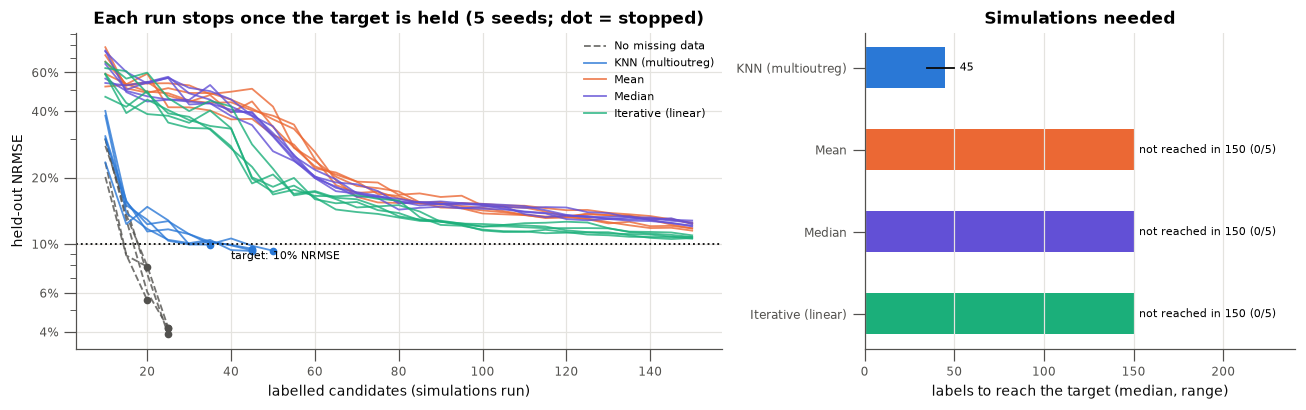

In [8]:
styles = {"No missing data": MUTED, **{k: c for k, (_, c) in IMPUTERS.items()}}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})

ax = axes[0]
for name, curves in runs.items():
    for i, c in enumerate(curves):
        ax.plot(c[:, 0], c[:, 1], color=styles[name], lw=1.2, alpha=0.8,
                ls="--" if name == "No missing data" else "-", label=name if i == 0 else None)
        if labels_to_target(c) is not None:
            ax.plot(c[-1, 0], c[-1, 1], "o", color=styles[name], ms=4)
ax.axhline(TOL, color=INK, ls=":", lw=1.2)
ax.text(N0 + 30, TOL * 0.93, f"target: {TOL:.0%} NRMSE", va="top", fontsize=7)
ax.set(yscale="log", xlabel="labelled candidates (simulations run)", ylabel="held-out NRMSE",
       title=f"Each run stops once the target is held ({len(SEEDS)} seeds; dot = stopped)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks([0.04, 0.06, 0.1, 0.2, 0.4, 0.6])
ax.legend(loc="upper right")

ax = axes[1]
names = [n for n in runs if n != "No missing data"]
for row, name in enumerate(names):
    hits = [labels_to_target(c) for c in runs[name]]
    vals = [h if h is not None else BUDGET for h in hits]
    reached = sum(h is not None for h in hits)
    ax.barh(row, np.median(vals), color=styles[name], height=0.5)
    ax.plot([min(vals), max(vals)], [row, row], color=INK, lw=1.2)
    note = f"{np.median(vals):.0f}" if reached == len(hits) else f"not reached in {BUDGET} ({reached}/{len(hits)})"
    ax.text(max(vals) + 3, row, note, va="center", fontsize=7)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set(xlim=(0, BUDGET * 1.6), xlabel="labels to reach the target (median, range)",
       title="Simulations needed")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Reading the plot:**

- **With KNN imputation every run reaches the 10% target and stops, after a median of 45
  simulations.** The GP is trained and scored on inputs close to the true ones, so the
  max-variance acquisition is steering by a sensible model.
- **With mean, median or linear MICE imputation no run reaches the target.** Each spends the
  full budget of 150 simulations, more than three times KNN's, and ends at about 11–12% NRMSE.
  The filled inputs put labelled candidates in the wrong place in input space, so the GP has
  to treat the mismatch as noise. Extra labels then average that noise down slowly instead
  of resolving the response.
- **KNN still costs labels compared with complete data.** The dashed no-missing-data runs
  stop after 20–25 simulations, at 4–8% NRMSE. KNN's small fill error flattens its curve
  just under the target, so a much tighter target would not be reached by any imputer
  here. Choose the target with the data quality in mind.

---
<a id='caveats'></a>
## 5. Caveats: When KNN Is Not the Best Choice

This example favours KNN on purpose, and the conditions should be stated plainly:

- **The always-present composition columns pin down each candidate.** If the columns
  that drive the relationships are the ones going missing, every imputer degrades. In a
  quick check with gaps in all six columns, every method stalled near 30% NRMSE.
- **All inputs share one scale.** `impute_train_test` measures distance in raw units, so
  with mixed units it behaves like the mean (see the [imputation
  tutorial](imputation_methods.ipynb)).
- **The gaps are missing completely at random.** If the expensive characterisation was
  skipped for a particular kind of candidate, every imputer is biased.
- **A stronger model-based imputer can beat KNN.** Iterative imputation with a tree
  ensemble learns the same nonlinear links as KNN, but with sharper fits. The cell below
  runs it through the same loop.

In [9]:
trees = fit_apply(IterativeImputer(ExtraTreesRegressor(n_estimators=50, random_state=0),
                                   max_iter=10, random_state=0))
a, b = trees(X_pool, X_test)
tree_curves = [pool_active_learning(a, Y_pool, b, Y_test, s) for s in SEEDS]

compare = pd.DataFrame({
    name: {
        "fill RMSE": np.sqrt(np.mean((pool - X_pool_true)[gaps] ** 2)),
        "median labels to target": np.median([labels_to_target(c) or np.inf for c in curves]),
    }
    for name, pool, curves in [
        ("KNN (multioutreg)", filled["KNN (multioutreg)"][0], runs["KNN (multioutreg)"]),
        ("Iterative (extra trees)", a, tree_curves),
    ]
}).T
compare.round(3)

,fill RMSE,median labels to target
KNN (multioutreg),0.039,45.0
Iterative (extra trees),0.026,30.0


The tree-based iterative imputer has a lower fill error and reaches the target with fewer
labels than KNN. It also costs far more: it fits a forest per column, per iteration. So the
fair summary is:

| Imputer | Fill quality here | Reaches 10% target within 150 labels |
|---|---|---|
| Mean / median | Poor (one constant per column) | No |
| Iterative, linear | Poor for nonlinear links | No |
| **KNN (`impute_train_test`)** | **Good** | **Yes** |
| Iterative, extra trees | Best | Yes, with fewer labels, at a higher compute cost |

`multioutreg`'s KNN default clearly beats the simple and linear alternatives whenever the
inputs share a scale and related candidates are present in the pool. A tree-based iterative
imputer is worth trying when the imputation step is cheap compared with a simulation.